# MUM – zadanie 3

In [1]:
library(tidyverse)
library(car)
library(caret)
library(caTools)
library(gridExtra)

options(repr.plot.width = 14, repr.plot.height = 8)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Ładowanie wymaganego pakietu: carData




Dołączanie pakietu: 'car'




Następujący obiekt został zakryty z 'package:dplyr':

    recode




Następujący obiekt został zakryty z 'package:purrr':

    some




Ładowanie wymaganego pakietu: lattice




Dołączanie pakietu: 'caret'




Następujący obiekt został zakryty z 'package:purrr':

    lift





Dołączanie pakietu: 'gridExtra'




Następujący obiekt został zakryty z 'package:dplyr':

    combine




Dane dotyczą kampanii telemarketingowej portugalskiego banku (lata 2008-2010, 45 211 klientów). Zmienna objaśniana y mówi,
czy klient po rozmowie założył lokatę terminową (yes/no). Ponieważ y ma tylko dwie wartości, buduję model regresji
logistycznej (glm z rodziną binomial), tak jak na zajęciach na zbiorze CCS.

In [2]:
bank <- read_delim("bank-full.csv", delim = ";", col_types = "iffffifffifiiiiff")

glimpse(bank)

Rows: 45,211
Columns: 17
$ age       <int> 58, 44, 33, 47, 33, 35, 28, 42, 58, 43, 41, 29, 53, 58, 57, …
$ job       <fct> management, technician, entrepreneur, blue-collar, unknown, …
$ marital   <fct> married, single, married, married, single, married, single, …
$ education <fct> tertiary, secondary, secondary, unknown, unknown, tertiary, …
$ default   <fct> no, no, no, no, no, no, no, yes, no, no, no, no, no, no, no,…
$ balance   <int> 2143, 29, 2, 1506, 1, 231, 447, 2, 121, 593, 270, 390, 6, 71…
$ housing   <fct> yes, yes, yes, yes, no, yes, yes, yes, yes, yes, yes, yes, y…
$ loan      <fct> no, no, yes, no, no, no, yes, no, no, no, no, no, no, no, no…
$ contact   <fct> unknown, unknown, unknown, unknown, unknown, unknown, unknow…
$ day       <int> 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, …
$ month     <fct> may, may, may, may, may, may, may, may, may, may, may, may, …
$ duration  <int> 261, 151, 76, 92, 198, 139, 217, 380, 50, 55, 222, 137, 517,…
$ campaign  <in

# Wstępna analiza zmiennych
Kolumny pogrupowałem tematycznie:
* klient - age (wiek), job (zawód), marital (stan cywilny), education (wykształcenie), default (niespłacony kredyt),
  balance (średnie saldo w euro), housing (kredyt hipoteczny), loan (kredyt gotówkowy)
* obecna kampania - contact (rodzaj kontaktu), day i month (dzień i miesiąc ostatniego kontaktu), duration (długość ostatniej
  rozmowy w sekundach), campaign (liczba kontaktów w tej kampanii)
* poprzednie kampanie - pdays (dni od ostatniego kontaktu, -1 = nie było kontaktu), previous (liczba wcześniejszych
  kontaktów), poutcome (wynik poprzedniej kampanii)
* zmienna objaśniana - y (czy klient założył lokatę)

In [3]:
summary(bank)

prop.table(table(bank$y))

# y jako liczba 0/1 - średnia z niej to odsetek klientów, którzy założyli lokatę
bank$y.num <- ifelse(bank$y == "yes", 1, 0)

      age                 job           marital          education    
 Min.   :18.00   blue-collar:9732   married :27214   tertiary :13301  
 1st Qu.:33.00   management :9458   single  :12790   secondary:23202  
 Median :39.00   technician :7597   divorced: 5207   unknown  : 1857  
 Mean   :40.94   admin.     :5171                    primary  : 6851  
 3rd Qu.:48.00   services   :4154                                     
 Max.   :95.00   retired    :2264                                     
                 (Other)    :6835                                     
 default        balance       housing      loan            contact     
 no :44396   Min.   : -8019   yes:25130   no :37967   unknown  :13020  
 yes:  815   1st Qu.:    72   no :20081   yes: 7244   cellular :29285  
             Median :   448                           telephone: 2906  
             Mean   :  1362                                            
             3rd Qu.:  1428                                            



       no       yes 
0.8830152 0.1169848 

Braków danych nie ma (brak informacji jest zapisany jako osobna kategoria unknown). Lokatę założyło tylko 11,7% klientów,
więc klasy są mocno niezrównoważone. Model, który zawsze mówi „no”, miałby już 88,3% trafności, i do tego trzeba
porównywać wyniki.

pdays = -1 i previous = 0 występują w tych samych 36 954 wierszach, czyli u klientów, z którymi wcześniej nie było kontaktu.

In [4]:
bank %>%
  mutate(przedzial = ntile(duration, 5)) %>%
  group_by(przedzial) %>%
  summarize(od = min(duration), do = max(duration), odsetek_yes = round(mean(y.num), 3))

przedzial,od,do,odsetek_yes
<int>,<int>,<int>,<dbl>
1,0,89,0.007
2,89,147,0.037
3,147,223,0.079
4,223,368,0.130
5,368,4918,0.332


duration bardzo mocno wiąże się z y: przy najkrótszych rozmowach lokatę zakłada 0,7% klientów, a przy najdłuższych 33%.
Długość rozmowy znamy jednak dopiero po telefonie, kiedy klient już podjął decyzję. Model ma przewidywać, do kogo warto
zadzwonić, więc duration pomijam (byłby to przeciek informacji, jak TOTLGIVE w zadaniu 1).

## Zmienne kategoryczne
Dla każdej kategorii liczę średnią z y.num, czyli odsetek klientów, którzy założyli lokatę (jak średnie dla Region na zajęciach).

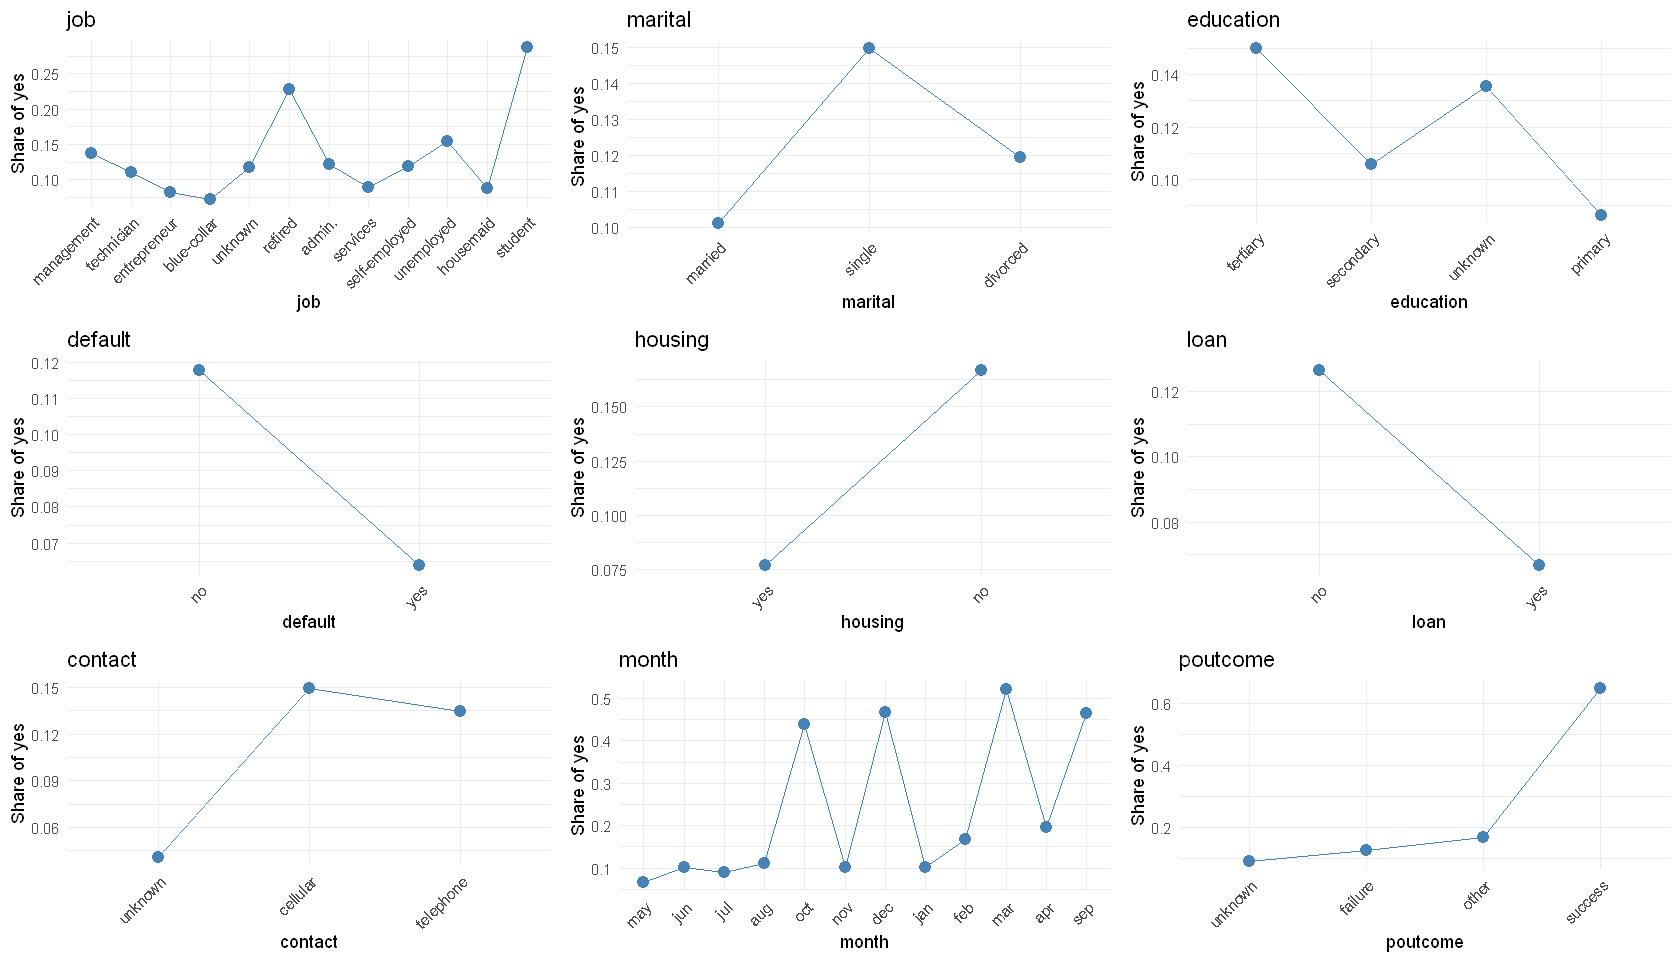

In [5]:
kategoryczne <- c("job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome")

wykresy <- lapply(kategoryczne, function(kol) {
  bank %>%
    group_by(.data[[kol]]) %>%
    summarize(odsetek_yes = mean(y.num)) %>%
    ggplot(aes(x = .data[[kol]], y = odsetek_yes, group = 1)) +
    geom_point(size = 3, color = "steelblue") +
    geom_line(color = "steelblue") +
    labs(title = kol, x = kol, y = "Share of yes") +
    theme_minimal() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
})
grid.arrange(grobs = wykresy, ncol = 3)

* poutcome - jeśli poprzednia kampania zakończyła się sukcesem, lokatę zakłada aż 65% klientów (przy braku wcześniejszego kontaktu 9%)
* month - duże różnice: w marcu, wrześniu, październiku i grudniu ok. 44-52%, a w maju tylko 7% (w maju dzwoniono najwięcej)
* contact - przy nieznanym rodzaju kontaktu tylko 4%, przy komórce 15%
* job - najczęściej studenci (29%) i emeryci (23%), najrzadziej robotnicy (7%)
* housing i loan - klienci z kredytem zakładają lokatę rzadziej (8% i 7% wobec 17% i 13%)
* marital, education, default - mniejsze różnice

## Zmienne numeryczne
Tak jak na zajęciach dzielę zmienne numeryczne na przedziały i liczę odsetek yes w każdym z nich. Dla age i balance
używam ntile. campaign i previous mają bardzo dużo powtarzających się wartości (np. previous = 0 u 82% klientów),
więc tu ntile dzieliłby te same wartości na różne grupy. Dlatego przedziały ustawiam ręcznie funkcją cut.

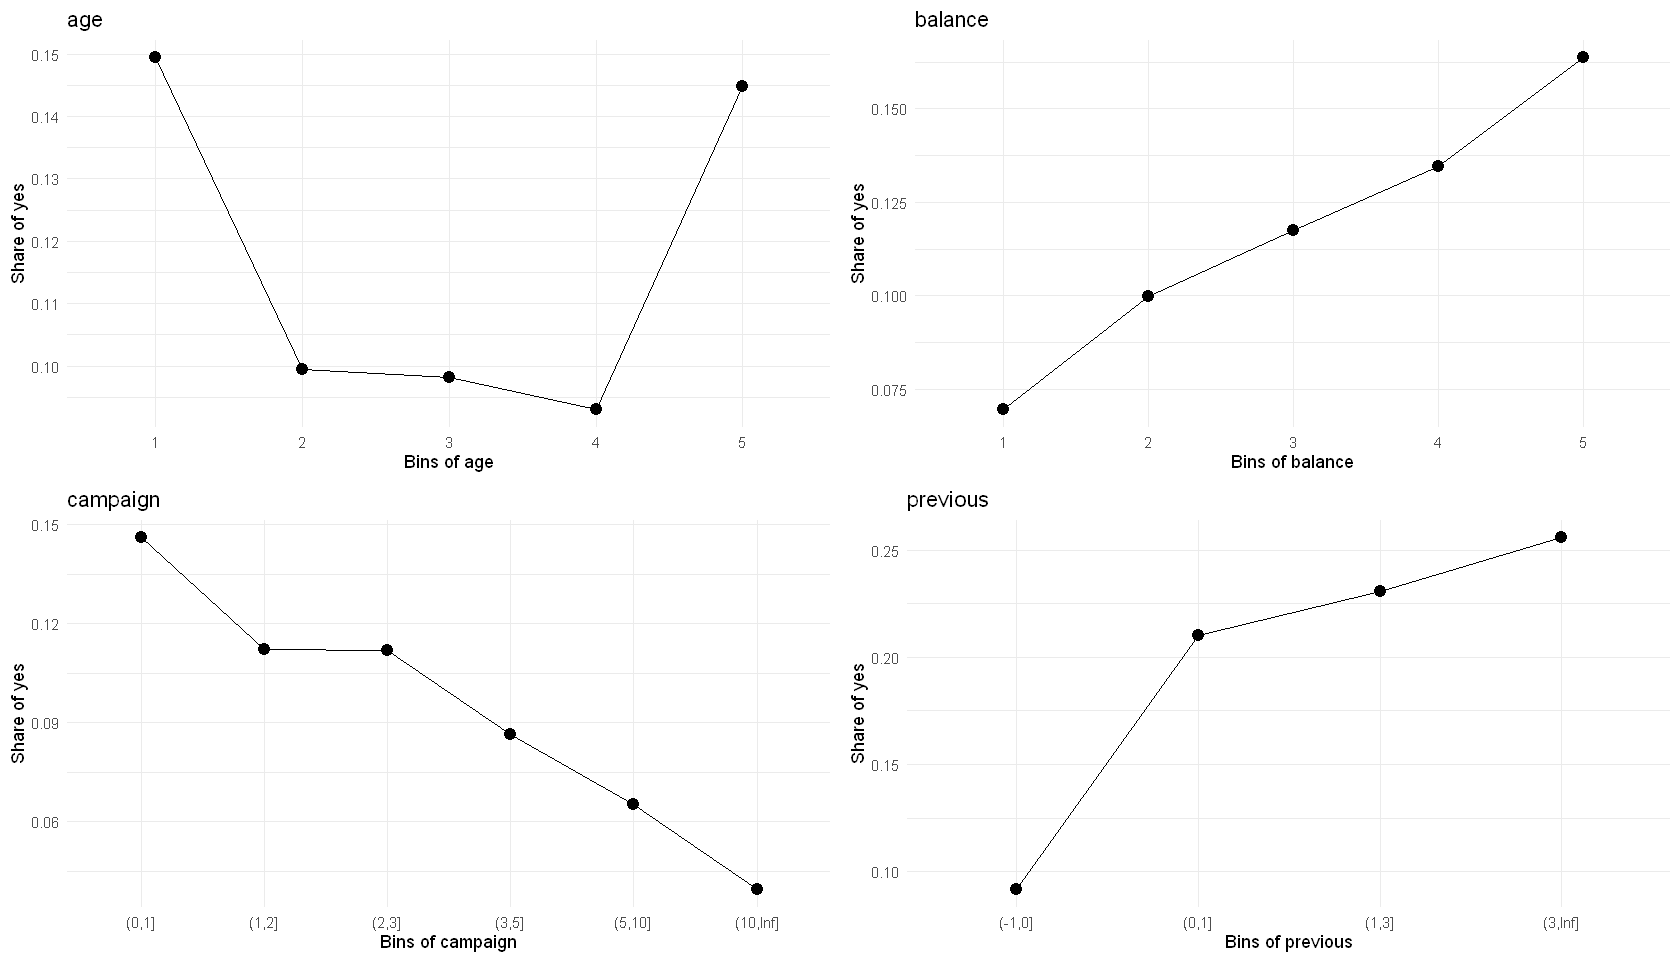

In [6]:
przedzialy <- list(
  age      = bank %>% mutate(przedzial = ntile(age, 5)),
  balance  = bank %>% mutate(przedzial = ntile(balance, 5)),
  campaign = bank %>% mutate(przedzial = cut(campaign, c(0, 1, 2, 3, 5, 10, Inf))),
  previous = bank %>% mutate(przedzial = cut(previous, c(-1, 0, 1, 3, Inf)))
)

wykresy <- lapply(names(przedzialy), function(kol) {
  przedzialy[[kol]] %>%
    group_by(przedzial) %>%
    summarize(odsetek_yes = mean(y.num)) %>%
    ggplot(aes(x = factor(przedzial), y = odsetek_yes, group = 1)) +
    geom_point(size = 3) +
    geom_line() +
    labs(title = kol, x = paste("Bins of", kol), y = "Share of yes") +
    theme_minimal()
})
grid.arrange(grobs = wykresy, ncol = 2)

* age - zależność w kształcie litery U: najmłodsi (do 32 lat) i najstarsi (powyżej 51) zakładają lokatę częściej (ok. 15%)
  niż osoby w średnim wieku (ok. 9-10%). Prosta liniowa tego nie opisze, dlatego w modelu nieliniowym dodam age^2.
* balance - im wyższe saldo, tym częściej lokata (od 7% do 16%)
* campaign - im więcej telefonów w tej kampanii, tym gorzej (od 15% przy jednym do 4% przy ponad dziesięciu), spadek coraz
  wolniejszy, więc pasuje log(campaign)
* previous - duży skok między 0 (9%) a co najmniej jednym wcześniejszym kontaktem (21-26%), dalej już niewielki wzrost,
  więc pasuje log(previous + 1)

# Podział na zbiór treningowy i testowy
Dzielę dane 80/20 z zachowaniem proporcji y, żeby ocenić modele na danych, których nie widziały.

In [7]:
set.seed(1234)
sample_set <- sample.split(bank$y, SplitRatio = 0.8)
bank_train <- subset(bank, sample_set == TRUE)
bank_test <- subset(bank, sample_set == FALSE)

prop.table(table(bank_train$y))
prop.table(table(bank_test$y))


       no       yes 
0.8830214 0.1169786 


       no       yes 
0.8829905 0.1170095 

# Model logistyczny - model max
Model ze wszystkimi zmiennymi oprócz duration. Jakość mierzę współczynnikiem R2 McFaddena.

In [8]:
GLM.MAX <- glm(y ~ age + job + marital + education + default + balance + housing + loan + contact + day + month +
                 campaign + pdays + previous + poutcome,
               family = binomial(logit), data = bank_train)
summary(GLM.MAX)

1 - (GLM.MAX$deviance / GLM.MAX$null.deviance) # McFadden R2

Anova(GLM.MAX)


Call:
glm(formula = y ~ age + job + marital + education + default + 
    balance + housing + loan + contact + day + month + campaign + 
    pdays + previous + poutcome, family = binomial(logit), data = bank_train)

Coefficients:
                     Estimate Std. Error z value Pr(>|z|)    
(Intercept)        -3.438e+00  1.260e-01 -27.295  < 2e-16 ***
age                 1.290e-03  2.186e-03   0.590 0.555108    
jobtechnician      -2.889e-02  6.406e-02  -0.451 0.652039    
jobentrepreneur    -1.182e-01  1.171e-01  -1.009 0.312872    
jobblue-collar     -7.807e-02  7.369e-02  -1.060 0.289359    
jobunknown          3.432e-02  2.203e-01   0.156 0.876203    
jobretired          5.026e-01  9.135e-02   5.502 3.76e-08 ***
jobadmin.           5.497e-02  7.324e-02   0.751 0.452933    
jobservices        -1.867e-02  8.459e-02  -0.221 0.825337    
jobself-employed    5.491e-02  9.965e-02   0.551 0.581645    
jobunemployed       1.681e-01  1.054e-01   1.595 0.110651    
jobhousemaid       -2.652e

[1] 0.1633487

,LR Chisq,Df,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>
age,0.34796545,1,5.552671e-01
job,71.39158561,11,6.638700e-11
marital,47.50814487,2,4.827668e-11
education,24.36455239,3,2.096342e-05
default,0.97100983,1,3.244285e-01
balance,12.70180992,1,3.653018e-04
housing,150.98958842,1,1.053571e-34
loan,46.18292946,1,1.077114e-11
contact,360.97973767,2,4.113826e-79


R2 McFaddena wynosi 0,163. Według tablicy Anova nieistotne są age, default, day, pdays i previous.
age wychodzi nieistotna, bo jej zależność od y ma kształt U, a model liniowy tego nie widzi.

Dla porównania model z duration ma R2 McFaddena aż 0,338, ale z opisanego wyżej powodu nie da się go użyć.

In [9]:
GLM.DUR <- update(GLM.MAX, . ~ . + duration)
1 - (GLM.DUR$deviance / GLM.DUR$null.deviance) # McFadden R2 z duration

[1] 0.3379862

# Redukcja zmiennych - step

In [10]:
GLM.STEP <- step(GLM.MAX, direction = "both", trace = 0)
formula(GLM.STEP)

1 - (GLM.STEP$deviance / GLM.STEP$null.deviance) # McFadden R2

y ~ job + marital + education + balance + housing + loan + contact + 
    month + campaign + poutcome

[1] 0.163182

step usunął age, default, day, pdays i previous, czyli dokładnie zmienne nieistotne według Anova. R2 McFaddena się
praktycznie nie zmienił (0,163), a model ma o pięć zmiennych mniej.

# Model nieliniowy
Na podstawie wykresów dodaję age^2 i logarytmuję campaign oraz previous. Najpierw sprawdzam zera, bo log(0) nie istnieje.

In [11]:
bank %>%
  summarise(across(c(age, campaign, previous), ~ sum(.x == 0), .names = "zera_{.col}"))

zera_age,zera_campaign,zera_previous
<int>,<int>,<int>
0,0,36954


previous ma zera, więc jak na zajęciach używam log(previous + 1). campaign zawsze wynosi co najmniej 1, więc wystarczy log(campaign).

In [12]:
bank_train <- bank_train %>% mutate(log.campaign = log(campaign), log.previous = log(previous + 1))
bank_test <- bank_test %>% mutate(log.campaign = log(campaign), log.previous = log(previous + 1))

GLM.NONLIN <- glm(y ~ age + I(age^2) + job + marital + education + default + balance + housing + loan + contact + day +
                    month + log.campaign + log.previous + pdays + poutcome,
                  family = binomial(logit), data = bank_train)

1 - (GLM.NONLIN$deviance / GLM.NONLIN$null.deviance) # McFadden R2

Anova(GLM.NONLIN)

[1] 0.1664444

,LR Chisq,Df,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>
age,70.3387919,1,4.994582e-17
I(age^2),75.7529282,1,3.214740e-18
job,21.1646204,11,3.170510e-02
marital,27.5292761,2,1.052189e-06
education,27.3736682,3,4.915473e-06
default,1.0154826,1,3.135930e-01
balance,12.5888896,1,3.880466e-04
housing,140.3022795,1,2.286192e-32
loan,43.9778502,1,3.321130e-11


Po dodaniu age^2 obie zmienne wieku są bardzo istotne. Najmniejsze prawdopodobieństwo lokaty wypada ok. 44 roku życia.
log.previous też jest teraz istotna. Nieistotne zostały default, day i pdays, więc je usuwam.

In [13]:
GLM.MIX <- glm(y ~ age + I(age^2) + job + marital + education + balance + housing + loan + contact + month +
                 log.campaign + log.previous + poutcome,
               family = binomial(logit), data = bank_train)
summary(GLM.MIX)

1 - (GLM.MIX$deviance / GLM.MIX$null.deviance) # McFadden R2

Anova(GLM.MIX)


Call:
glm(formula = y ~ age + I(age^2) + job + marital + education + 
    balance + housing + loan + contact + month + log.campaign + 
    log.previous + poutcome, family = binomial(logit), data = bank_train)

Coefficients:
                     Estimate Std. Error z value Pr(>|z|)    
(Intercept)        -1.494e+00  2.509e-01  -5.953 2.64e-09 ***
age                -8.772e-02  1.046e-02  -8.384  < 2e-16 ***
I(age^2)            9.922e-04  1.142e-04   8.687  < 2e-16 ***
jobtechnician      -2.955e-02  6.403e-02  -0.461 0.644483    
jobentrepreneur    -1.198e-01  1.170e-01  -1.024 0.305960    
jobblue-collar     -7.504e-02  7.379e-02  -1.017 0.309171    
jobunknown         -8.103e-03  2.212e-01  -0.037 0.970779    
jobretired          1.730e-01  1.018e-01   1.699 0.089242 .  
jobadmin.           4.150e-02  7.330e-02   0.566 0.571331    
jobservices        -3.343e-02  8.466e-02  -0.395 0.692960    
jobself-employed    3.932e-02  9.992e-02   0.393 0.693982    
jobunemployed       1.740e-01  

[1] 0.1663637

,LR Chisq,Df,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>
age,70.18755,1,5.392575e-17
I(age^2),75.61552,1,3.446417e-18
job,21.30353,11,3.035939e-02
marital,27.43320,2,1.103968e-06
education,27.50204,3,4.619958e-06
balance,12.95426,1,3.191945e-04
housing,142.09046,1,9.291846e-33
loan,45.44609,1,1.568984e-11
contact,351.82924,2,3.992560e-77


# Ocena modeli na zbiorze testowym
Dla każdego modelu liczę:
* trafność i czułość (jaki odsetek klientów z yes model wykrył) przy progu 0,5
* odsetek yes wśród 10% klientów z najwyższym przewidywanym prawdopodobieństwem, czyli jak dobrze model wskazuje,
  do kogo dzwonić w pierwszej kolejności

In [14]:
ocena <- function(model) {
  prob <- predict(model, bank_test, type = "response")
  pred <- factor(ifelse(prob > 0.5, "yes", "no"), levels = levels(bank_test$y))
  cm <- confusionMatrix(pred, bank_test$y, positive = "yes")
  top10 <- bank_test$y[order(prob, decreasing = TRUE)][1:round(0.1 * nrow(bank_test))]
  c(McFadden_R2 = round(1 - model$deviance / model$null.deviance, 3),
    AIC = round(AIC(model)),
    trafnosc = round(unname(cm$overall["Accuracy"]), 3),
    czulosc = round(unname(cm$byClass["Sensitivity"]), 3),
    yes_w_top10 = round(mean(top10 == "yes"), 3))
}

rbind("max" = ocena(GLM.MAX), "step" = ocena(GLM.STEP), "nieliniowy zredukowany" = ocena(GLM.MIX))

,McFadden_R2,AIC,trafnosc,czulosc,yes_w_top10
max,0.163,21924,0.895,0.197,0.501
step,0.163,21918,0.895,0.196,0.501
nieliniowy zredukowany,0.166,21841,0.896,0.210,0.496


* Trafność wszystkich modeli to ok. 0,895, czyli niewiele więcej niż 0,883 modelu, który zawsze mówi „no”.
* Przy progu 0,5 model wykrywa tylko ok. 20% klientów z yes, bo takich klientów jest mało i rzadko dostają
  prawdopodobieństwo powyżej 0,5.
* Wśród 10% klientów z najwyższym prawdopodobieństwem lokatę zakłada ok. 50%, czyli ponad 4 razy więcej niż średnio (11,7%).
  Model dobrze więc wskazuje, do kogo warto dzwonić w pierwszej kolejności.
* Model nieliniowy ma najniższe AIC, najwyższy R2 McFaddena i najwyższą czułość, a w top 10% wypada prawie tak samo jak pozostałe.

In [15]:
bank_test$prob <- predict(GLM.MIX, bank_test, type = "response")

for (prog in c(0.5, 0.2)) {
  pred <- factor(ifelse(bank_test$prob > prog, "yes", "no"), levels = levels(bank_test$y))
  cm <- confusionMatrix(pred, bank_test$y, positive = "yes")
  print(paste("próg", prog))
  print(cm$table)
  print(round(c(cm$overall["Accuracy"], cm$byClass[c("Sensitivity", "Precision")]), 3))
}

[1] "próg 0.5"
          Reference
Prediction   no  yes
       no  7877  836
       yes  107  222
   Accuracy Sensitivity   Precision 
      0.896       0.210       0.675 
[1] "próg 0.2"
          Reference
Prediction   no  yes
       no  7425  570
       yes  559  488
   Accuracy Sensitivity   Precision 
      0.875       0.461       0.466 


Obniżenie progu z 0,5 do 0,2 podwaja czułość (z 21% do 46%). Kosztem jest więcej fałszywych alarmów: wśród wskazanych
klientów yes wybiera 47% zamiast 67%. Przy telemarketingu lepiej zadzwonić do kilku osób za dużo niż przegapić chętnych,
więc niższy próg ma tu sens.

In [16]:
# klienci, którzy odmówili, a według modelu mieli największą szansę na lokatę
bank_test %>%
  filter(y == "no") %>%
  arrange(desc(prob)) %>%
  select(age, job, balance, contact, month, poutcome, prob) %>%
  head(5)

age,job,balance,contact,month,poutcome,prob
<int>,<fct>,<int>,<fct>,<fct>,<fct>,<dbl>
94,retired,1234,cellular,mar,unknown,0.9211417
46,management,461,cellular,mar,success,0.8934609
31,student,64,cellular,sep,success,0.8855373
61,retired,1058,cellular,oct,success,0.8793550
27,management,390,cellular,oct,success,0.8777303


# Wybór najlepszego modelu
Najlepszy jest model nieliniowy zredukowany:
y ~ age + age^2 + job + marital + education + balance + housing + loan + contact + month + log(campaign) + log(previous + 1) + poutcome
(R2 McFaddena 0,166, najniższe AIC). Najbardziej liczą się wynik poprzedniej kampanii, miesiąc i rodzaj kontaktu.